# CosMx Pancreas data visualizations

- Cell type composition

In [11]:
import os

# LRZ home
if os.path.exists("/dss/dsshome1/05/di93tig"):
    print('LRZ cluster')
    CLUSTER = 'LRZ'
    BASE_DIR_REPO = "/dss/dsshome1/05/di93tig/1_projects" 
    BASE_DIR_PROJECT = "/dss/dssfs03/tumdss/pn36po/pn36po-dss-0002/di93tig/Projects/A3_InterScale"
elif os.path.exists("/home/icb/francesca.drummer/"):
    print('HPC cluster')
    CLUSTER = 'HPC'
    BASE_DIR_REPO = "/home/icb/francesca.drummer/1-Projects/A3_InterScale/"
    BASE_DIR_PROJECT = "/lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/"
else:
    print('unkown')
    CLUSTER = 'unknown'
DATA = "melton25"

HPC cluster


In [12]:
import sys
from pathlib import Path

# Add project root to path (go up 2 levels from notebook location)
project_root = Path(f'{BASE_DIR_REPO}/InterScale_reproducibility')
print(project_root)
sys.path.insert(0, str(project_root))

/home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility


In [13]:
import yaml
import matplotlib.pyplot as plt
import os

with open(os.path.join(BASE_DIR_REPO, "InterScale_reproducibility/figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]
CELL_TYPE_COLORS = config["palettes"][DATA]

In [14]:
import scanpy as sc
import squidpy as sq

import pandas as pd
import numpy as np

import warnings
warnings.filterwarnings('ignore')

## Figure setting

In [15]:
import yaml
import matplotlib.pyplot as plt

with open(os.path.join(BASE_DIR_REPO, "InterScale_reproducibility/figures/config.yml"), "r") as f:
    config = yaml.safe_load(f)

PALETTE = config["palettes"]["continuous"]
CELL_TYPE_COLORS = config["palettes"]["melton25"]

## Load data

In [16]:
adata = sc.read_h5ad(os.path.join(BASE_DIR_PROJECT, 'data', 'melton25.h5ad'))
adata

AnnData object with n_obs × n_vars = 386727 × 979
    obs: 'fov', 'Area', 'AspectRatio', 'CenterX_global_px', 'CenterY_global_px', 'Width', 'Height', 'Mean.MembraneStain', 'Max.MembraneStain', 'Mean.PanCK', 'Max.PanCK', 'Mean.GCG', 'Max.GCG', 'Mean.CD3', 'Max.CD3', 'Mean.DAPI', 'Max.DAPI', 'cell_ID', 'condition', 'slide', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_NegPrb', 'log1p_total_counts_NegPrb', 'pct_counts_NegPrb', 'n_genes', 'cell_type_coarse', 'CellTypes_max', 'slide_fov', 'slide_condition', 'split', 'split_0', 'split_1', 'split_2', 'globalX', 'globalY', 'sliding_window_square', 'sliding_window_h', 'sliding_window_v'
    obsm: 'X_pca', 'X_umap', 'spatial', 'spatial_fov'
    layers: 'counts', None (.X)

## Sliding window creation

In [17]:
WINDOW_SIZE = 400

In [18]:
WINDOW_SIZES = [400, 800, 1200, 1600, 2000, 3000]
coords = pd.DataFrame(np.asarray(adata.obsm['spatial'])[:, :2],
                      columns=['x', 'y'], index=adata.obs_names)
rows = []

for w in WINDOW_SIZES:
    key = f'sliding_window_{w}'
    if key not in adata.obs:
        sq.tl.sliding_window(adata, library_key='slide_fov',
                             window_size=w, sliding_window_key=key)

    # observed=True avoids empty-category zeros skewing min/mean
    counts = adata.obs.groupby(key, observed=True).size()

    # actual spatial extent per window (mean of x- and y-span)
    ext = coords.groupby(adata.obs[key].values, observed=True).agg(['min', 'max'])
    span = ((ext[('x', 'max')] - ext[('x', 'min')]) +
            (ext[('y', 'max')] - ext[('y', 'min')])) / 2

    rows.append(dict(window_size=w,
                     cells_min=counts.min(), cells_max=counts.max(),
                     cells_mean=counts.mean(), cells_std=counts.std(),
                     size_min=span.min(), size_max=span.max(),
                     size_mean=span.mean(), size_std=span.std()))

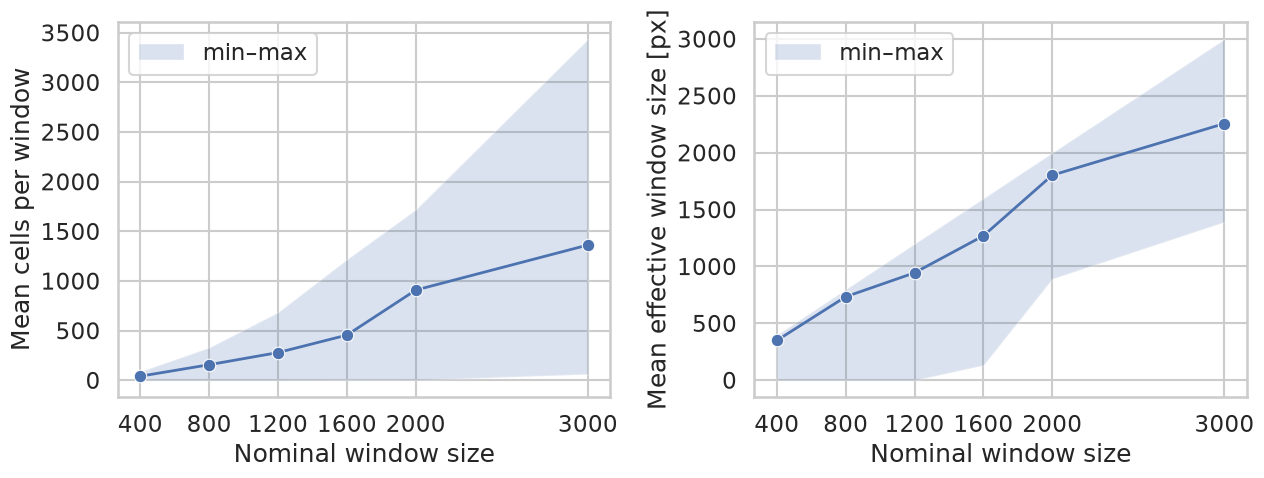

In [19]:
import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt


df = pd.DataFrame(rows)

sns.set_theme(style='whitegrid', context='talk')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (y, lo, hi, label) in zip(
        axes,
        [('cells_mean', 'cells_min', 'cells_max', 'Cells per window'),
         ('size_mean',  'size_min',  'size_max',  'Effective window size [px]')]):
    sns.lineplot(data=df, x='window_size', y=y, marker='o',
                 markersize=9, linewidth=2, ax=ax)
    ax.fill_between(df['window_size'], df[lo], df[hi], alpha=0.2, label='min–max')
    ax.set_xlabel('Nominal window size')
    ax.set_ylabel(f'Mean {label.lower()}')
    ax.set_xticks(WINDOW_SIZES)
    ax.legend()

fig.tight_layout()
plt.show()

In [20]:
adata.write_h5ad(os.path.join(BASE_DIR_PROJECT, 'data', 'melton25_sliding_window.h5ad'))

## Training six models — the WandB sweep

**Sweep: [`z63vmk20` — melton25-node-reg-sliding-window-ablation](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/z63vmk20)**

The six `sliding_window_{400,800,1200,1600,2000,3000}` columns written above are trained as **one
grid sweep**: 6 window sizes × 3 seeds = **18 trials**, everything else held fixed at the winning
configuration of the melton25 reconstruction hyperparameter sweep `sio2fsjm` (run `ycjcovv2`) — the
same configuration `scripts/melton_jimenez_25/celltype_reconstruction_mse.py` reports. Re-tuning per
arm would let the tuning absorb part of the window-size effect, which is the one thing this
ablation is trying to isolate.

### Why the window size is a sweep *arm*

A window size implies three config values that have to move **together**:

| key | why it changes with the window |
|---|---|
| `dataset.sample_key` | which `obs` column the windows live in |
| `model.global_component.parameters.max_seq_len` | attention pads every graph to `max_seq_len`, so it must be ≥ that column's largest window over **all** splits (inference runs on every cell, not just train). It cannot be shared: a global 3436 would make the w400 arm pay (3436/89)² ≈ 1500× the attention cost of the sequence it actually contains. |
| `dataset.name` | reaches the checkpoint filename through `get_model_filename_prefix`, so without it all six arms overwrite one file |

wandb searches the **cartesian product** of its parameters, so declaring those three separately
asks for 6³ = 216 trials of which 6 are meaningful. `interscale.config.sweep.load_arms` resolves an
`arms:` block locally instead and declares only the arm *name* to wandb — see
`interscale/config_files/sweeps/sliding_window_melton25.yaml`.

`max_seq_len` per arm is that column's largest window over all three splits:

| arm | window column | n windows | max cells → `max_seq_len` | batch |
|---|---|---|---|---|
| w400 | `sliding_window_400` | 9604 | 89 | 64 |
| w800 | `sliding_window_800` | 2479 | 330 | 32 |
| w1200 | `sliding_window_1200` | 1389 | 685 | 16 |
| w1600 | `sliding_window_1600` | 851 | 1218 | 8 |
| w2000 | `sliding_window_2000` | 426 | 1720 | 8 |
| w3000 | `sliding_window_3000` | 284 | 3436 | 4 |

Below `max_seq_len`, `pad_batch` random-subsamples the window every step **and**
`get_model_output` stores an attention matrix narrower than the window, which makes
`compute_hierarchical_net_flow` fail with a shape mismatch rather than a wrong number.

`split` is assigned per **slide** (train = `Run5211_S1`, val = `Run5211_S2`, test = `Run5211_S3`) and
squidpy builds windows within `slide_fov`, so **no window straddles a split** at any window size —
which is what makes the arms comparable at all. Otherwise a larger window would leak test cells
into training.

### How it was submitted

```bash
cd ~/1-Projects/A3_InterScale/interscale

# 1. register the sweep (login node, no GPU)
python src/interscale/main_sweep.py --dataset melton25_sw --task node_reg \
    --model_type CombinedModel --sweep_goal robustness \
    --sweep_cfg config_files/sweeps/sliding_window_melton25.yaml \
    --metric val_concordance_corr --create_only
# -> SWEEP_ID=z63vmk20

# 2. three agents, six trials each
for i in 1 2 3; do
  SWEEP_ID=z63vmk20 sbatch scripts/run.sh melton25_sw node_reg \
      --sweep_cfg config_files/sweeps/sliding_window_melton25.yaml \
      --sweep_goal robustness --metric val_concordance_corr --count 6
done
```

In [21]:
import importlib.util
from pathlib import Path

SCRIPTS = Path(BASE_DIR_REPO) / "InterScale_reproducibility" / "scripts" / "melton_jimenez_25"


def load_script(filename):
    """Import one of the numbered analysis scripts as a module.

    They are `import`ed rather than duplicated so the notebook and the batch jobs cannot drift
    apart. A plain `import` will not do it: the module names start with a digit.
    """
    path = SCRIPTS / filename
    spec = importlib.util.spec_from_file_location(path.stem, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module


extract = load_script("5a_sliding_window_attention.py")   # sweep -> attention masks
ablation = load_script("5b_sliding_window_ablation.py")    # attention masks -> ablation

SWEEP_ID = extract.SWEEP_ID
SWEEP_URL = extract.SWEEP_URL
ATTN_DIR = extract.OUT           # where the attention masks live
ABLATION_DIR = ablation.OUT      # where the tables and figures live

print(f"sweep      {SWEEP_ID}\n           {SWEEP_URL}")
print(f"attention  {ATTN_DIR}")
print(f"ablation   {ABLATION_DIR}")

sweep      z63vmk20
           https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/z63vmk20
attention  /lustre/groups/ml01/projects/2024_spatial_long_range_GT_francesca.drummer/results/melton25_revision/sliding_window/attention
ablation   /home/icb/francesca.drummer/1-Projects/A3_InterScale/InterScale_reproducibility/figures/melton25/sliding_window_ablation


In [22]:
# The 18 runs, straight from the wandb API. `resolved_*` are summary keys main_sweep.py writes
# after applying each trial, so what a run actually trained is readable without unpacking the
# nested config blob -- and `checkpoint_prefix` is the filename that run wrote.
runs = extract.fetch_sweep_runs(SWEEP_ID)

print(f"{len(runs)} runs, states: {runs['state'].value_counts().to_dict()}")
runs[[
    "run_name", "state", "arm", "window_size", "seed",
    "resolved_max_seq_len", "val_concordance_corr", "val_r2", "test_concordance_corr", "epoch",
]]

wandb: ERROR Failed to detect the name of this notebook. You can set it manually with the WANDB_NOTEBOOK_NAME environment variable to enable code saving.
wandb: [wandb.Api()] Loaded credentials for https://api.wandb.ai from /home/icb/francesca.drummer/.netrc.


18 runs, states: {'finished': 18}


,run_name,state,arm,window_size,seed,resolved_max_seq_len,val_concordance_corr,val_r2,test_concordance_corr,epoch
0,dual_melton25_sw400_regr_node_42_GCN_self-attn...,finished,w400,400.0,42,89,0.018448,-0.008616,0.019518,60
1,dual_melton25_sw400_regr_node_43_GCN_self-attn...,finished,w400,400.0,43,89,0.017091,-0.014969,0.018047,44
2,dual_melton25_sw400_regr_node_44_GCN_self-attn...,finished,w400,400.0,44,89,0.018338,-0.009740,0.019640,62
3,dual_melton25_sw800_regr_node_42_GCN_self-attn...,finished,w800,800.0,42,330,0.017446,-0.002163,0.019318,94
4,dual_melton25_sw800_regr_node_43_GCN_self-attn...,finished,w800,800.0,43,330,0.016074,-0.019955,0.017176,55
5,dual_melton25_sw800_regr_node_44_GCN_self-attn...,finished,w800,800.0,44,330,0.016106,-0.013581,0.017105,64
6,dual_melton25_sw1200_regr_node_42_GCN_self-att...,finished,w1200,1200.0,42,685,0.015516,-0.009925,0.018878,89
7,dual_melton25_sw1200_regr_node_43_GCN_self-att...,finished,w1200,1200.0,43,685,0.013765,-0.022180,0.014905,40
8,dual_melton25_sw1200_regr_node_44_GCN_self-att...,finished,w1200,1200.0,44,685,0.015160,-0.013082,0.017382,66
9,dual_melton25_sw1600_regr_node_42_GCN_self-att...,finished,w1600,1600.0,42,1218,0.015410,-0.019318,0.016288,55


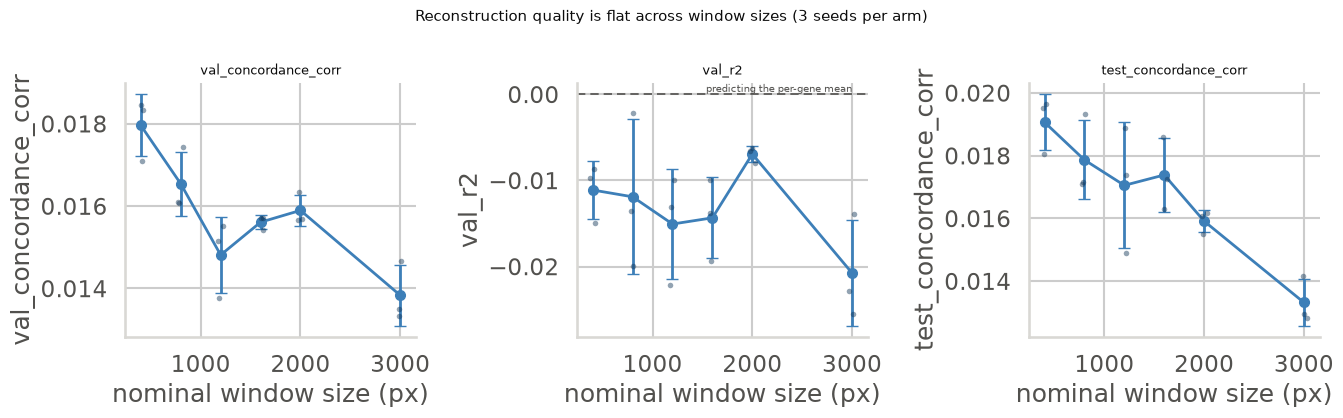

,,n,val_ccc,val_ccc_sd,val_r2,test_ccc,epochs
arm,window_size,,,,,,
w400,400.0,3,0.0180,0.0008,-0.0111,0.0191,55.3333
w800,800.0,3,0.0165,0.0008,-0.0119,0.0179,71.0000
w1200,1200.0,3,0.0148,0.0009,-0.0151,0.0171,65.0000
w1600,1600.0,3,0.0156,0.0002,-0.0143,0.0174,69.3333
w2000,2000.0,3,0.0159,0.0004,-0.0069,0.0159,77.0000
w3000,3000.0,3,0.0138,0.0007,-0.0208,0.0133,62.0000


In [23]:
# Reconstruction quality against window size.
#
# Read this FIRST, because it is what motivates everything below: the loss does not resolve the
# ablation. Every arm sits at val R2 within noise of 0 and val CCC 0.013-0.018, i.e. a model that
# can only see 40 cells at a time reconstructs expression about as well as one that sees 1362.
# Whatever a smaller window misses, it does not show up here -- it has to be read off the
# attention.
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4), sharex=True)
for ax, metric in zip(axes, ["val_concordance_corr", "val_r2", "test_concordance_corr"]):
    g = runs.groupby("window_size")[metric].agg(["mean", "std"]).reset_index()
    ax.errorbar(g["window_size"], g["mean"], yerr=g["std"],
                marker="o", ms=7, lw=2, capsize=4, color="#3d7fb8")
    sns.stripplot(data=runs, x="window_size", y=metric, ax=ax,
                  native_scale=True, color="#0f3355", alpha=0.45, size=4, jitter=0.08)
    if metric.endswith("r2"):
        ax.axhline(0, color="#52514e", lw=1.2, ls=(0, (5, 3)))
        ax.text(runs["window_size"].max(), 0, " predicting the per-gene mean",
                ha="right", va="bottom", fontsize=7.5, color="#52514e")
    ax.set_xlabel("nominal window size (px)")
    ax.set_ylabel(metric)
    ax.set_title(metric, fontsize=9.5)

fig.suptitle("Reconstruction quality is flat across window sizes (3 seeds per arm)", y=1.03)
fig.tight_layout()
plt.show()

runs.groupby(["arm", "window_size"]).agg(
    n=("run_id", "size"),
    val_ccc=("val_concordance_corr", "mean"), val_ccc_sd=("val_concordance_corr", "std"),
    val_r2=("val_r2", "mean"), test_ccc=("test_concordance_corr", "mean"),
    epochs=("epoch", "mean"),
).sort_index(level="window_size").round(4)

## Loading the models from the sweep and saving the attention masks

`5a_sliding_window_attention.py` walks the sweep, rebuilds each trial's config from the registry +
the arms yaml, loads the checkpoint that trial wrote, and runs `get_model_output` to obtain
`obsm['_attn_matrix']`.

**What `_attn_matrix` actually is.** Not raw attention — the Chefer et al. (2021) relevance matrix
that `interscale.tl.self_attn_relevance.generate_relevance` builds as

$$I \leftarrow \mathbf{I}_n, \qquad I \mathrel{+}= \big(\overline{\nabla \odot A}\big)^+ I \quad \text{per layer}$$

i.e. identity, then gradient-weighted, head-averaged, positively-clamped attention accumulated on
top. So the **diagonal starts at exactly 1** and comes out at ~99% of the total mass (row sums ≈
1.01). That is a construction constant, not the model attending to each cell itself — the
interaction signal is the ~1% off the diagonal, and every distance-resolved quantity below
subtracts the diagonal exactly before looking at anything.

**On the held-out slide only.** `Run5211_S3` is the test slide for every arm (splits are per slide),
it carries both conditions (ND 51,365 / T1D 100,230 cells), and no window straddles the slide
boundary. It is also the only tractable choice: `get_model_output` allocates one
`n_cells × max_seq_len` frame and does a full-frame masked assignment per window, so on all 386,727
cells the w400 arm would do 9,604 such assignments against a 386,727-row frame.

Products per `(arm, seed)`:

| file | contents |
|---|---|
| `attn/<arm>_seed<seed>.h5` | the **raw attention masks**, one group per window: `attn` (float16, *n×n*), `cell_index`, `type_codes`, `coords` |
| `flows/<arm>_seed<seed>.npz` | per-window relevance **sums**, binned by (sender type, receiver type, distance), plus `diag_sums` — the diagonal per cell type, kept apart so it can be subtracted exactly |
| `windows/<arm>.npz` | the matching pair **counts** + window metadata — model-independent, so once per arm |
| `reference_pair_distances.npz` | every within-FOV pair of the slide, binned the same way (the coverage denominator) |

Labels and coordinates are stored *inside* each window group so the permutation test can relabel a
window without re-deriving a mapping from `cell_index` back into the slide AnnData — the one step
where an off-by-one would silently produce a plausible null distribution for the wrong cells.

Submitted with:

```bash
cd ~/1-Projects/A3_InterScale/InterScale_reproducibility
sbatch scripts/melton_jimenez_25/run_sliding_window_attention.sh
```

> **A confound worth stating.** `prepare_a2d_dataset` overwrites
> `spatial_neigbors_kwargs.library_key` with the window column, so the **local** graph is cut at
> window boundaries too: a 40-cell w400 window loses a far larger fraction of its radius-110
> neighbours to the boundary than a 1362-cell w3000 window does. This is inherent to the design
> (training builds its graphs the same way), but it means an arm-to-arm difference is a difference
> in *what the windowing exposes*, local and global together — not in the transformer's range alone.

In [24]:
import h5py

# What was written, and how to get at one window's attention mask.
inventory = []
for arm in extract.ARMS:
    for seed in extract.SEEDS:
        h5_path = ATTN_DIR / "attn" / f"{arm}_seed{seed}.h5"
        npz_path = ATTN_DIR / "flows" / f"{arm}_seed{seed}.npz"
        inventory.append({
            "arm": arm, "window_size": extract.arm_window_size(arm), "seed": seed,
            "attn_h5_MB": round(h5_path.stat().st_size / 1e6, 1) if h5_path.exists() else None,
            "flows_MB": round(npz_path.stat().st_size / 1e6, 2) if npz_path.exists() else None,
        })
inventory = pd.DataFrame(inventory)
print(f"total attention on disk: {inventory['attn_h5_MB'].sum():.0f} MB")
display(inventory)

# One window's mask. Rows are senders, columns receivers, in the order of `cell_index` -- the same
# orientation compute_hierarchical_net_flow reads out of obsm['_attn_matrix'].
#
# Note what this is: NOT raw attention, but the Chefer et al. (2021) relevance matrix built by
# interscale.tl.self_attn_relevance.generate_relevance as
#     I = eye(n);   for each layer:   I += (grad * attn, clamped, head-averaged) @ I
# The diagonal therefore starts at 1 by construction, which is why row sums come out just above 1
# and why the diagonal alone is ~99% of the mass. Everything interaction-related is the remainder.
with h5py.File(ATTN_DIR / "attn" / "w3000_seed42.h5", "r") as h5:
    names = list(h5["windows"])
    biggest = max(names, key=lambda n: h5["windows"][n].attrs["n_cells"])
    g = h5["windows"][biggest]
    A = np.asarray(g["attn"], dtype=np.float32)
    types = np.asarray(g["type_codes"])
    print(f"\nwindow {biggest}: {A.shape[0]} cells, FOV {g.attrs['slide_fov']}, "
          f"condition {g.attrs['condition']}")
    off = A[~np.eye(A.shape[0], dtype=bool)]
    print(f"row sums          mean {A.sum(axis=1).mean():.4f}")
    print(f"diagonal          mean {np.diag(A).mean():.4f}  ({np.diag(A).sum() / A.sum():.1%} of the mass)")
    print(f"off-diagonal      mean {off.mean():.3e}  max {off.max():.3e}")

total attention on disk: 3224 MB


,arm,window_size,seed,attn_h5_MB,flows_MB
0,w400,400.0,42,29.4,1.55
1,w400,400.0,43,32.0,1.69
2,w400,400.0,44,33.6,1.72
3,w800,800.0,42,39.3,1.02
4,w800,800.0,43,48.6,1.03
5,w800,800.0,44,52.6,1.04
6,w1200,1200.0,42,82.8,0.69
7,w1200,1200.0,43,113.5,0.69
8,w1200,1200.0,44,101.4,0.69
9,w1600,1600.0,42,166.8,0.58



window 3_11_window_0: 3436 cells, FOV 3_11, condition T1D
row sums          mean 1.0249
diagonal          mean 1.0000  (97.6% of the mass)
off-diagonal      mean 7.237e-06  max 1.286e-03


## Ablation: what is missed at smaller window sizes

`5b_sliding_window_ablation.py` answers the question at three levels, from the hardest constraint
outward:

1. **Structural** — which pairs a windowing can expose *at all*. Two cells in different windows
   never appear in the same attention block, at any strength, for any seed. No model involved; this
   is the ceiling everything else sits under.
2. **Attributed** — where the trained model actually puts its attention as a function of
   sender–receiver distance. A window can expose a long-range pair and the model can still ignore it.
3. **Inferred** — which cell-type interactions come out *significant*, and at which window size they
   first do. This is the permutation test of
   [`Interaction_analysis.ipynb`](https://github.com/theislab/InterScale_reproducibility/blob/main/notebooks/melton_jimenez_25/Interaction_analysis.ipynb),
   run once per arm.

The flow definition is reproduced exactly from
`interscale.evaluation.net_streams.compute_hierarchical_net_flow` — per window
`agg[s,r] = mean attention over (sender type s, receiver type r) pairs` (diagonal included), then
`net = agg.T - agg`, then divided by the window's own `max|net|`; then mean over the windows of each
`slide_fov`; then mean/sd over the samples of each condition. `--validate` asserts the vectorised
version against the real function to 1e-4.

It is vectorised because the reference makes one `adata[adata.obs[win] == w]` subset and 81 pandas
`.loc` calls **per window** — for the w400 arm that is 3,200 AnnData subsets and 260,000 `.loc`
calls, per seed, per permutation.

**Two corrections carried over from the reference notebook.** It aggregates with
`sample_key='fov'`, but `fov` ids repeat across the three slides here, so it has to be `slide_fov`;
and it passes `sample_key=` where `compute_hierarchical_net_flow` expects `window_key=`.

```bash
sbatch scripts/melton_jimenez_25/run_sliding_window_ablation.sh
# or, interactively:  python scripts/melton_jimenez_25/5b_sliding_window_ablation.py --validate
```

In [25]:
# Tables written by 5b. Re-run the script rather than recomputing here: the permutation test is
# 100 permutations x 18 (arm, seed) pairs, ~25 min on cpu_p.
coverage = pd.read_csv(ABLATION_DIR / "coverage_by_distance.csv")
attention = pd.read_csv(ABLATION_DIR / "attention_by_distance.csv")
recovery = pd.read_csv(ABLATION_DIR / "recovery.csv")
flows = pd.read_csv(ABLATION_DIR / "flow_matrices.csv")
permutation = pd.read_csv(ABLATION_DIR / "permutation_stats.csv")
detection = pd.read_csv(ABLATION_DIR / "detection_thresholds.csv")
partial = pd.read_csv(ABLATION_DIR / "partial_permutation.csv")
stability = pd.read_csv(ABLATION_DIR / "seed_stability.csv")

CELL_TYPES = ablation.load_windows("w3000")["cell_types"]
for name, t in [("coverage", coverage), ("attention", attention), ("recovery", recovery),
                ("flows", flows), ("permutation", permutation), ("detection", detection),
                ("partial", partial), ("stability", stability)]:
    print(f"{name:12} {len(t):7,} rows")
print(f"\ncell types ({len(CELL_TYPES)}): {CELL_TYPES}")

coverage         588 rows
attention        324 rows
recovery          18 rows
flows          4,374 rows
permutation    4,374 rows
detection         81 rows
partial       16,362 rows
stability          6 rows

cell types (9): [np.str_('Acinar'), np.str_('Alpha'), np.str_('Beta'), np.str_('Ductal'), np.str_('Endocrine'), np.str_('Endothelial'), np.str_('Fibroblasts'), np.str_('Immune'), np.str_('Mast')]


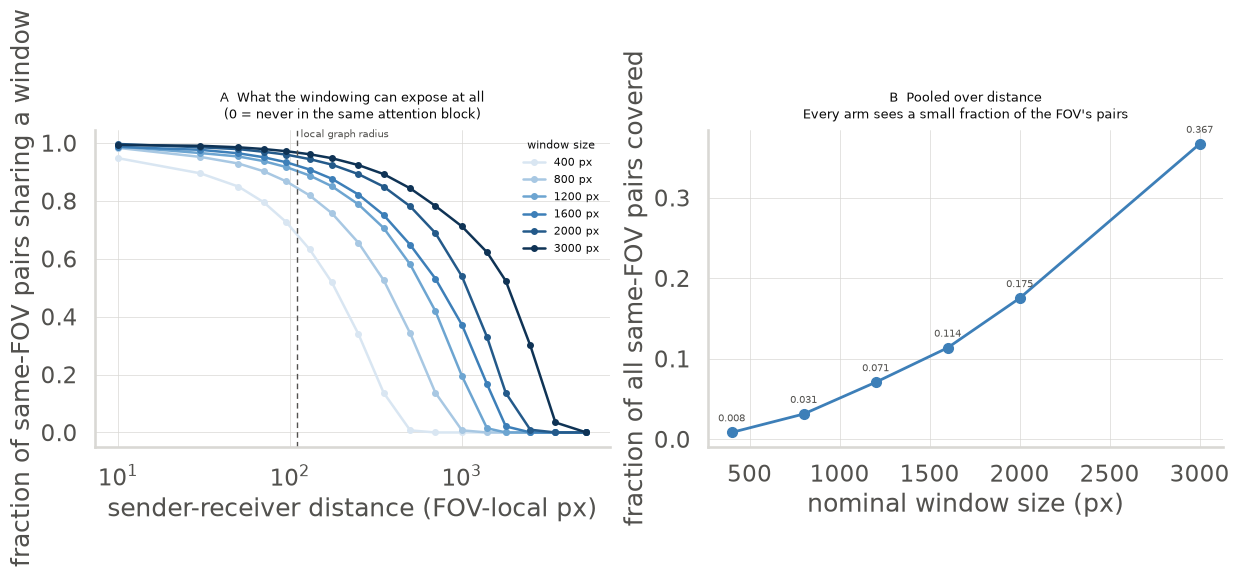

,arm,window_size,coverage_overall,coverage_below_110px,first_bin_below_1pct_px,first_bin_with_zero_px
0,w400,400,0.0083,0.7778,400.0,600.0
1,w800,800,0.0312,0.8932,800.0,1200.0
2,w1200,1200,0.0707,0.9320,1600.0,2000.0
3,w1600,1600,0.1135,0.9464,2000.0,3000.0
4,w2000,2000,0.1752,0.9675,2000.0,3000.0
5,w3000,3000,0.3668,0.9773,4000.0,NaN


In [26]:
# 1. STRUCTURAL -- what each windowing can expose at all.
#
# The denominator is same-FOV pairs. Windows are built within slide_fov, so two cells in different
# FOVs cannot share a window at ANY window size; counting them would drag every arm down by the
# same constant and hide the effect. Windows partition the cells (for w400, 9,604 windows of mean
# 40 cells cover all 386,727), so a pair shares at most one window and this is a fraction.
#
# Self-pairs are excluded from both sides: a cell always shares a window with itself, so leaving
# them in would put a spurious 1.0 in the first bin for every arm.
ablation.fig_coverage(coverage)
plt.show()

# The distance beyond which each arm covers essentially nothing -- the hard edge of what it can
# model, in the sense that no seed and no amount of training can put attention on a pair that
# never enters the same block.
pooled = coverage[coverage["bin"] >= 0]
cutoffs = []
for arm, g in pooled.groupby("arm", sort=False):
    g = g.sort_values("d_mid_px")
    below_1pct = g[g["coverage"] < 0.01]
    zero = g[g["pairs_covered"] == 0]
    local = g[g["d_hi_px"] <= 110]
    cutoffs.append({
        "arm": arm,
        "window_size": g["window_size"].iloc[0],
        "coverage_overall": g["pairs_covered"].sum() / g["pairs_possible"].sum(),
        "coverage_below_110px": local["pairs_covered"].sum() / local["pairs_possible"].sum(),
        "first_bin_below_1pct_px": below_1pct["d_lo_px"].iloc[0] if len(below_1pct) else np.nan,
        "first_bin_with_zero_px": zero["d_lo_px"].iloc[0] if len(zero) else np.nan,
    })
pd.DataFrame(cutoffs).round(4)

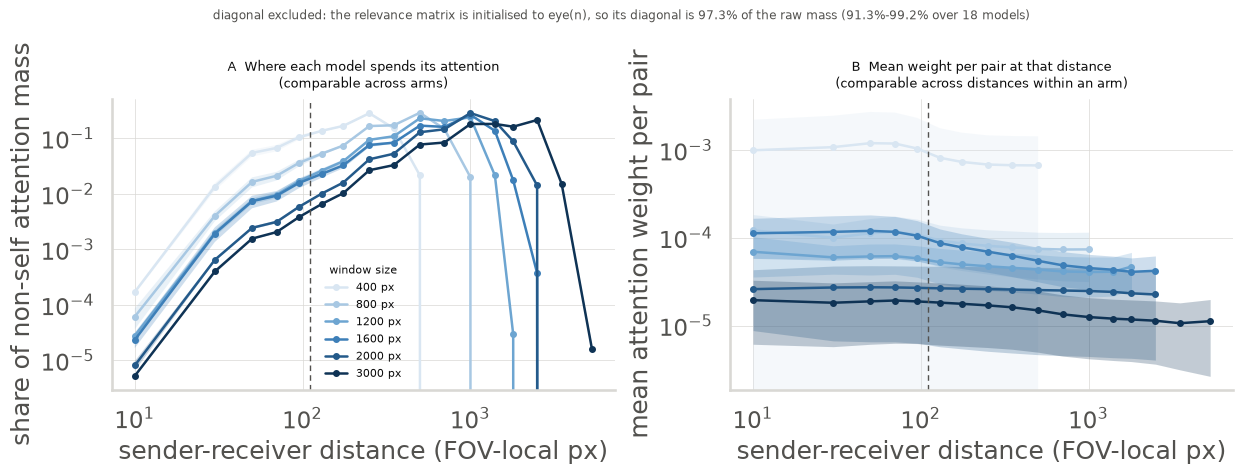

diagonal share of the raw relevance mass, per model (expect ~0.99 everywhere):


,seed,42,43,44
arm,window_size,,,
w400,400,0.9893,0.9851,0.9128
w800,800,0.9862,0.9920,0.9763
w1200,1200,0.9847,0.9715,0.9877
w1600,1600,0.9753,0.9711,0.9485
w2000,2000,0.9864,0.9503,0.9856
w3000,3000,0.9759,0.9533,0.9886


mean                             std  \
band              <=110px (local) >110px (global) <=110px (local)   
arm   window_size                                                   
w400  400                  0.2399          0.7601          0.0284   
w800  800                  0.0777          0.9223          0.0128   
w1200 1200                 0.0359          0.9641          0.0045   
w1600 1600                 0.0343          0.9657          0.0076   
w2000 2000                 0.0120          0.9880          0.0007   
w3000 3000                 0.0078          0.9922          0.0000   

                                   
band              >110px (global)  
arm   window_size                  
w400  400                  0.0284  
w800  800                  0.0128  
w1200 1200                 0.0045  
w1600 1600                 0.0076  
w2000 2000                 0.0007  
w3000 3000                 0.0000

In [27]:
# 2. ATTRIBUTED -- where the trained models actually put their attention.
#
# THE DIAGONAL IS EXCLUDED throughout, and that is not a detail. obsm['_attn_matrix'] is not raw
# attention: interscale.tl.self_attn_relevance.generate_relevance builds the Chefer et al. (2021)
# relevance matrix as
#     I = eye(n);   for each layer:   I += (grad * attn, clamped, head-averaged) @ I
# so the diagonal STARTS at exactly 1 and the attention terms accumulate on top. Its ~99% share of
# the total mass is that identity term -- a construction constant, not the model attending to each
# cell itself -- and it all sits at distance 0. Keep it in and every panel below is a plot of
# eye(n) with the real signal two orders of magnitude beneath it.
#
# It does not affect the flow matrices further down: the reference definition includes the diagonal
# in agg[s,s] and it cancels in net = agg.T - agg anyway.
#
# Two panels, because they answer different questions:
#   mass_share      fraction of the arm's off-diagonal mass at that distance. Comparable ACROSS
#                   arms: how each model spends the signal it has.
#   mean_attention  average weight on a pair at that distance. Comparable across distances WITHIN
#                   an arm, not across arms at one distance.
# The dashed line is the radius-110 local graph: everything left of it the GCN already sees.
ablation.fig_attention_distance(attention)
plt.show()

print("diagonal share of the raw relevance mass, per model (expect ~0.99 everywhere):")
display(
    attention[attention["bin"] == -1]
    .pivot_table(index=["arm", "window_size"], columns="seed", values="mass_share")
    .sort_index(level="window_size").round(4)
)

# How much of each arm's off-diagonal mass sits beyond the local graph's reach -- i.e. how much of
# the interaction signal is genuinely long-range rather than something the GCN could have supplied.
beyond = (
    attention[attention["bin"] >= 0]
    .assign(band=lambda d: np.where(d["d_hi_px"] <= 110, "<=110px (local)", ">110px (global)"))
    .groupby(["arm", "window_size", "seed", "band"], as_index=False)["mass_share"].sum()
    .pivot_table(index=["arm", "window_size"], columns="band", values="mass_share",
                 aggfunc=["mean", "std"])
    .sort_index(level="window_size")
)
beyond.round(4)

### Before going further: is the cell-type interaction structure reproducible?

Everything above is **geometry and attention mass** — no per-pair biological claim, and highly
seed-stable (the share of relevance beyond 110 px has an across-seed sd of 0.0007–0.028).

Everything *below* — the recovery curve, the permutation test, the per-pair detection thresholds —
depends on the cell-type × cell-type net-flow matrix being a reproducible property of the data
rather than of the random seed. **On these models it largely is not**, so this diagnostic comes
first and gates how far the rest can be read.

Three quantities, and what each one invalidates if it fails:

| quantity | gates |
|---|---|
| `flow_r_between_seeds` | the **recovery curve**. If the 3 seeds of one arm don't agree, "how much of w3000 does w400 recover" compares noise against noise — there is no reference to recover. |
| `sig_jaccard` | the **detection thresholds**. A pair significant in a different seed each time has no threshold. |
| `n_windows` | the **z column**. `z = (observed − null_mean)/null_std` and `null_std` shrinks with the number of windows averaged over, which spans 3426 (w400) → 100 (w3000), a 34× range. So `z` is not an effect size comparable across arms. |

This is reported rather than patched. With 3 seeds there is no honest way to rescue a per-pair
threshold from label sets agreeing at Jaccard ≈ 0.4, and the right conclusion is that this
particular question needs more seeds or a model that actually fits the data — recall every arm sits
at val R² ≈ 0.

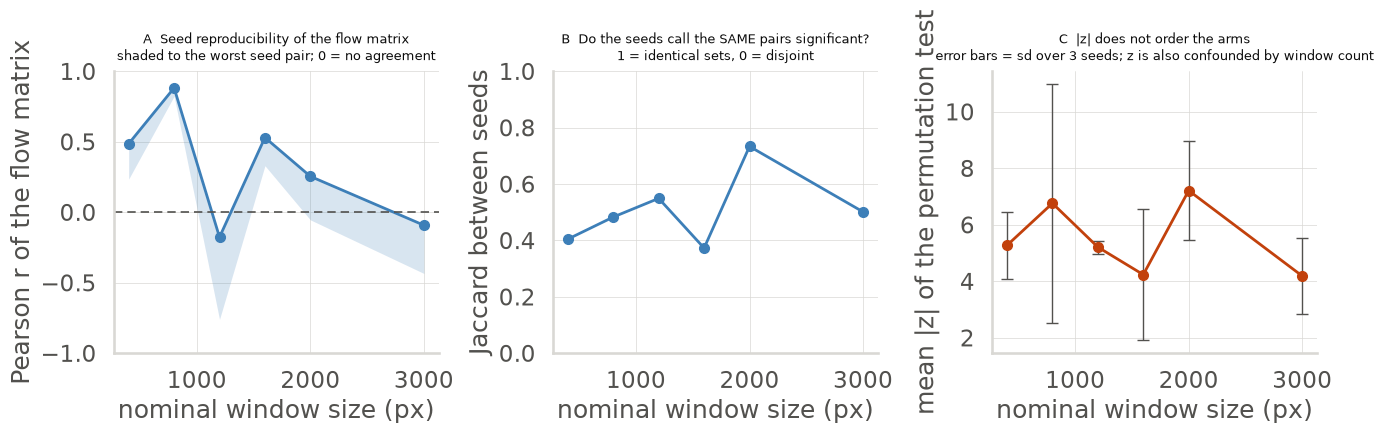

,window_size,n_windows,cells_per_window,flow_r_between_seeds,flow_r_min,n_sig_mean,n_sig_min,n_sig_max,sig_jaccard,mean_abs_z,abs_z_sd_between_seeds
0,400,3426,44.248,0.486,0.235,22.000,17,26,0.404,5.271,1.182
1,800,875,173.251,0.882,0.824,24.333,15,31,0.483,6.758,4.220
2,1200,496,305.635,-0.177,-0.760,25.333,20,29,0.549,5.207,0.232
3,1600,300,505.317,0.530,0.330,19.000,10,31,0.373,4.233,2.326
4,2000,150,1010.633,0.254,-0.054,30.333,29,31,0.733,7.209,1.742
5,3000,100,1515.950,-0.092,-0.434,25.000,17,30,0.501,4.185,1.341


4 of 6 arms have a between-seed flow correlation below 0.5 (worst seed pair: r = -0.76)
seeds agree on which pairs are significant at Jaccard 0.37-0.73
mean |z| spans 4.2-7.2 across arms, but its within-arm sd across seeds is up to 4.2 -- the arms are not separable on z


In [28]:
ablation.fig_seed_stability(stability)
plt.show()

display(stability[["window_size", "n_windows", "cells_per_window", "flow_r_between_seeds",
                   "flow_r_min", "n_sig_mean", "n_sig_min", "n_sig_max", "sig_jaccard",
                   "mean_abs_z", "abs_z_sd_between_seeds"]].round(3))

weak = stability[stability["flow_r_between_seeds"] < 0.5]
print(f"{len(weak)} of {len(stability)} arms have a between-seed flow correlation below 0.5 "
      f"(worst seed pair: r = {stability['flow_r_min'].min():.2f})")
print(f"seeds agree on which pairs are significant at Jaccard "
      f"{stability['sig_jaccard'].min():.2f}-{stability['sig_jaccard'].max():.2f}")
print(f"mean |z| spans {stability['mean_abs_z'].min():.1f}-{stability['mean_abs_z'].max():.1f} "
      f"across arms, but its within-arm sd across seeds is up to "
      f"{stability['abs_z_sd_between_seeds'].max():.1f} -- the arms are not separable on z")

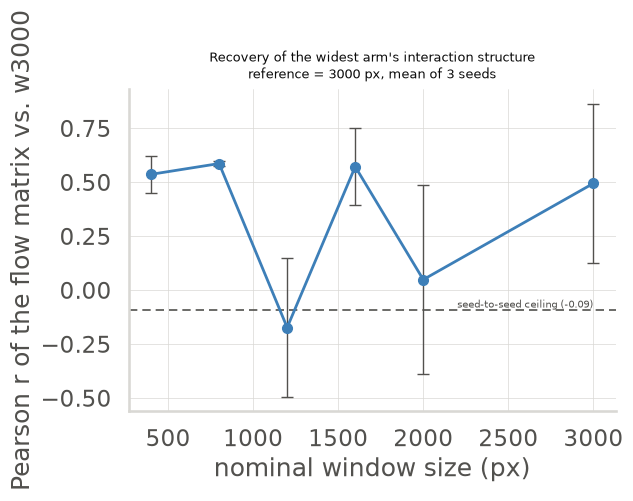

,,pearson,pearson_sd,spearman,cosine,ceiling
arm,window_size,,,,,
w400,400,0.537,0.085,0.524,0.537,-0.092
w800,800,0.586,0.010,0.598,0.586,-0.092
w1200,1200,-0.173,0.321,-0.111,-0.173,-0.092
w1600,1600,0.572,0.178,0.474,0.572,-0.092
w2000,2000,0.049,0.438,0.072,0.049,-0.092
w3000,3000,0.495,0.367,0.526,0.495,-0.092


seed-to-seed ceiling within w3000: -0.092
A ceiling at or below 0 means the reference arm does not reproduce itself across seeds,
so no row of this table can be read as 'this arm recovers X of the structure'.


In [29]:
# 3a. Recovery of the widest arm's flow structure -- SHOWN BUT NOT INTERPRETABLE HERE.
#
# Kept because it is the natural thing to ask and because the reason it fails is the finding: the
# dashed seed-to-seed ceiling is what the reference arm achieves against ITSELF across seeds, and
# it sits near 0. Every arm's correlation with the reference is therefore within noise of the
# reference's correlation with itself. Read the numbers as "no signal", not as a recovery curve.
ablation.fig_recovery(recovery)
plt.show()

rec_tbl = recovery.groupby(["arm", "window_size"]).agg(
    pearson=("pearson_vs_reference", "mean"), pearson_sd=("pearson_vs_reference", "std"),
    spearman=("spearman_vs_reference", "mean"), cosine=("cosine_vs_reference", "mean"),
    ceiling=("seed_ceiling", "first"),
).sort_index(level="window_size").round(3)
display(rec_tbl)
print(f"seed-to-seed ceiling within {recovery['reference_arm'].iloc[0]}: "
      f"{recovery['seed_ceiling'].iloc[0]:.3f}")
print("A ceiling at or below 0 means the reference arm does not reproduce itself across seeds,")
print("so no row of this table can be read as 'this arm recovers X of the structure'.")

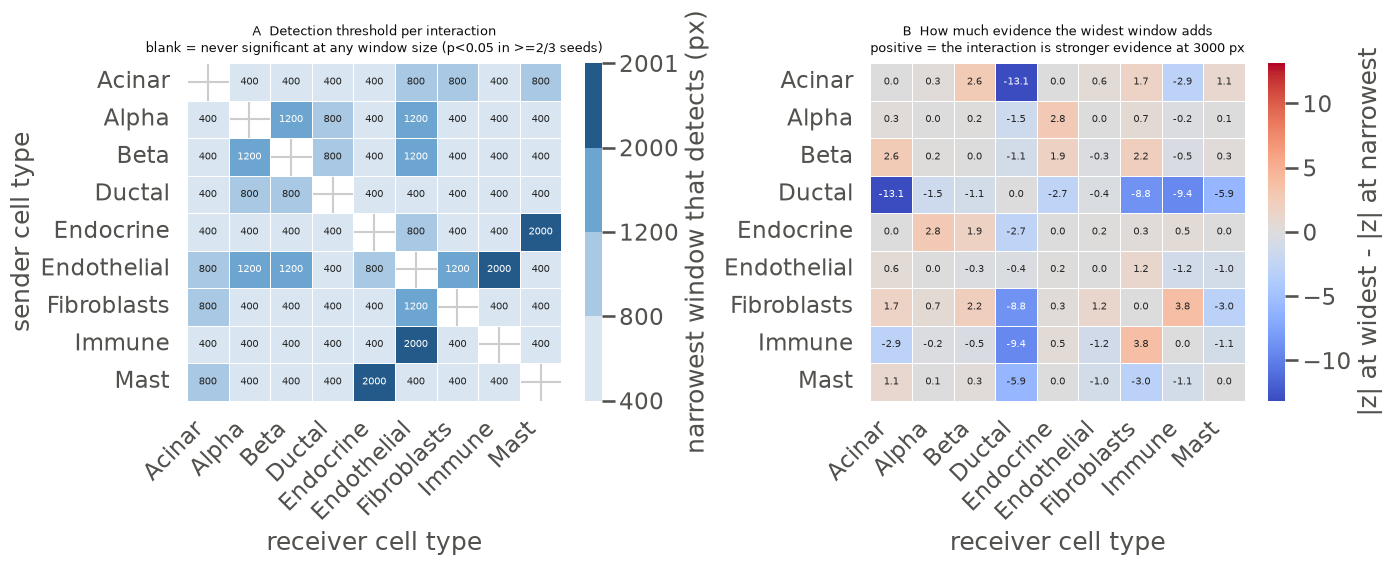

36 independent cell-type interactions
  never significant at any window size: 0
  first detected at   400 px:  24
  first detected at   800 px:   6
  first detected at  1200 px:   4
  first detected at  2000 px:   2

significant pairs (p<0.05) of 36, per arm per seed:


seed,42,43,44
window_size,,,
400,23,26,17
800,15,27,31
1200,20,29,27
1600,31,10,16
2000,31,31,29
3000,30,17,28


--- the only pairs needing 1200 px or wider ---


,sender,receiver,detected_at,n_arms_detected,flow_narrowest,flow_widest
60,Endothelial,Fibroblasts,1200.0,3,0.010,0.170
62,Alpha,Beta,1200.0,3,-0.002,0.057
64,Alpha,Endothelial,1200.0,3,0.000,-0.024
66,Beta,Endothelial,1200.0,3,-0.001,0.024
68,Endocrine,Mast,2000.0,2,0.001,-0.014
70,Endothelial,Immune,2000.0,2,-0.018,0.002


In [30]:
# 3b. Detection thresholds -- the smallest window at which each interaction becomes significant.
#
# Permutation null, identical to run_spatial_permutation_test in Interaction_analysis.ipynb: cell
# type labels shuffled WITHIN each window, preserving that window's composition and size and
# destroying only the spatial arrangement inside it. So the test asks "is this flow explained by
# which cell types are present, or by where they are?"
#
# WHAT THIS ACTUALLY SHOWED, which is not what the ablation predicted: essentially every
# interaction is already significant at the NARROWEST window. 24 of 36 at 400 px, and 0 of 36
# never significant at any arm -- the within-window label-permutation null is rejected for 17-31
# of 36 pairs at every window size. The test detects "there is spatial structure" (always true)
# rather than discriminating between window sizes.
#
# Read `detected_at` as a weak upper bound, and NOT the z columns as effect sizes across arms
# (see the reproducibility diagnostic above: z is confounded by window count, and the seeds agree
# on the significant set only at Jaccard ~0.4-0.7).
ablation.fig_detection_threshold(detection, CELL_TYPES)
plt.show()

# The net flow is ANTISYMMETRIC (net = agg.T - agg), so every off-diagonal interaction appears
# twice in `detection` with opposite signs and the 9 diagonal entries are structurally zero.
# Count the upper triangle: 36 independent interactions, not 81 rows.
undirected = detection[detection["sender"] < detection["receiver"]]
print(f"{len(undirected)} independent cell-type interactions")
print(f"  never significant at any window size: {undirected['detected_at'].isna().sum()}")
for size in sorted(undirected["detected_at"].dropna().unique()):
    print(f"  first detected at {int(size):5d} px: {int((undirected['detected_at'] == size).sum()):3d}")

# How many pairs each arm calls significant, per seed. Flat across arms is the point.
a = permutation[(permutation["condition"] == "all_samples")
                & (permutation["sender"] < permutation["receiver"])]
print("\nsignificant pairs (p<0.05) of 36, per arm per seed:")
display(a.groupby(["window_size", "seed"])["p"].apply(lambda p: (p < 0.05).sum()).unstack())

print("--- the only pairs needing 1200 px or wider ---")
late = undirected[undirected["detected_at"] >= 1200].sort_values("detected_at")
display(late[["sender", "receiver", "detected_at", "n_arms_detected",
              "flow_narrowest", "flow_widest"]].round(3))

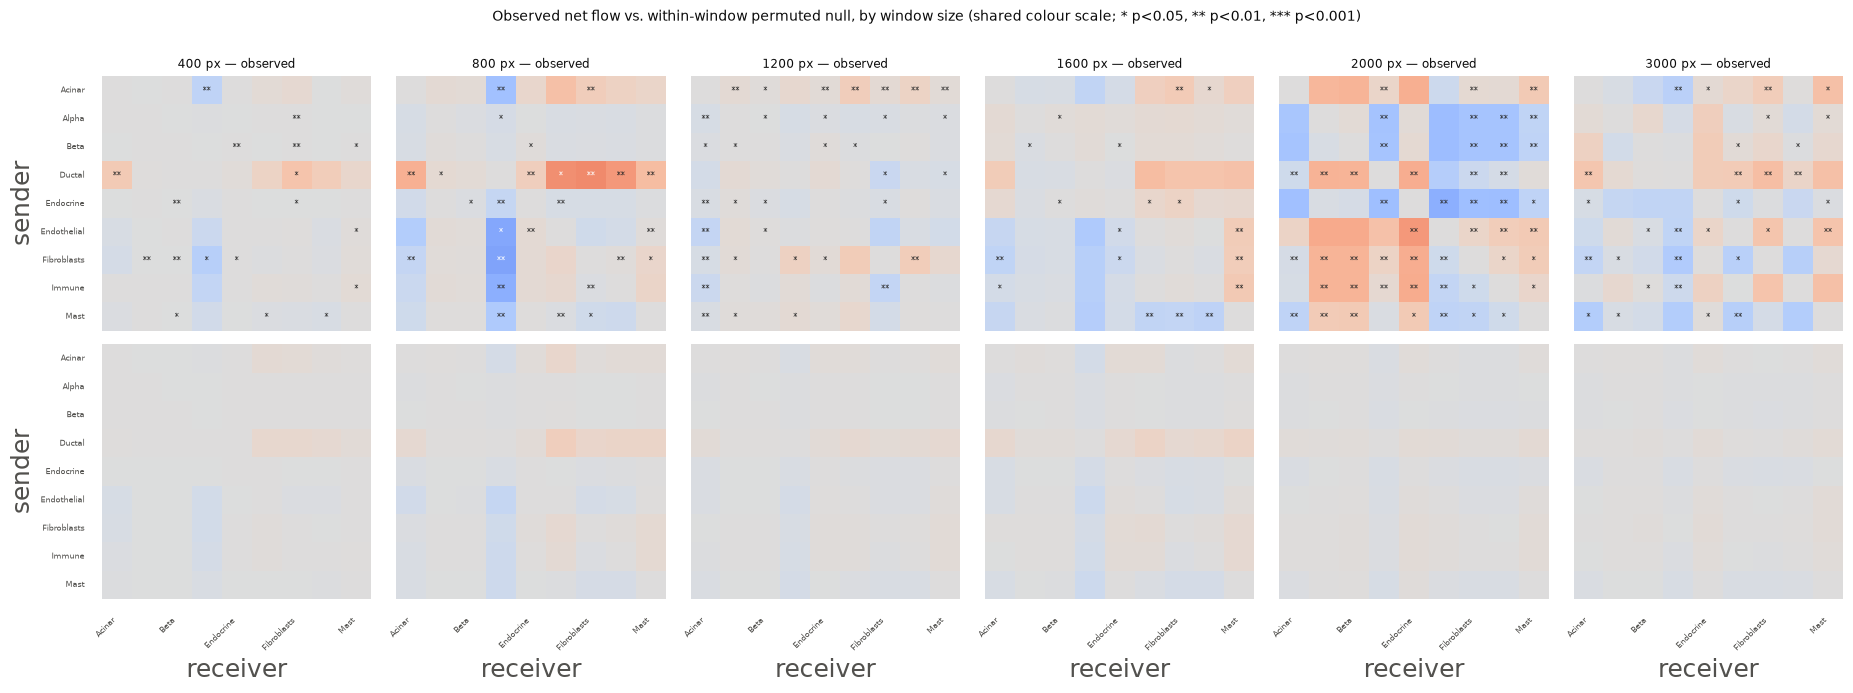


significant interactions (p<0.05) in ND, of 36, mean +/- sd over 3 seeds:
             mean  std
window_size           
400          18.0  1.7
800          18.0  6.2
1200         16.7  6.0
1600         14.3  9.5
2000         24.3  4.7
3000         17.0  6.9

significant interactions (p<0.05) in T1D, of 36, mean +/- sd over 3 seeds:
             mean   std
window_size            
400          20.3   6.4
800          23.0   9.2
1200         23.7   8.1
1600         15.0  11.5
2000         28.7   4.9
3000         23.3   7.6

Note the sd column: it is a large fraction of the mean for most arms, which is the
seed-instability of the previous section showing up again at the level of counts.


In [31]:
# 3c. Observed net flow beside its within-window null, one column per arm, on a shared colour
# scale. The null column is what a windowing can produce from composition alone -- where it looks
# like the observed column, that arm's flows carry no spatial information.
ablation.fig_observed_vs_null(permutation, CELL_TYPES)
plt.show()

# Per-condition: does the ND / T1D contrast survive at small window sizes? Counted on the upper
# triangle (36 independent pairs), same as everywhere else -- the per-condition flow matrices are
# antisymmetric too, so counting all 81 entries would double-report.
for cond in ["ND", "T1D"]:
    if cond in set(permutation["condition"]):
        c = permutation[(permutation["condition"] == cond)
                        & (permutation["sender"] < permutation["receiver"])]
        sig = (
            c.groupby(["window_size", "seed"])["p"].apply(lambda p: (p < 0.05).sum())
            .groupby("window_size").agg(["mean", "std"])
        )
        print(f"\nsignificant interactions (p<0.05) in {cond}, of 36, mean +/- sd over 3 seeds:")
        print(sig.round(1).to_string())

print("\nNote the sd column: it is a large fraction of the mean for most arms, which is the")
print("seed-instability of the previous section showing up again at the level of counts.")

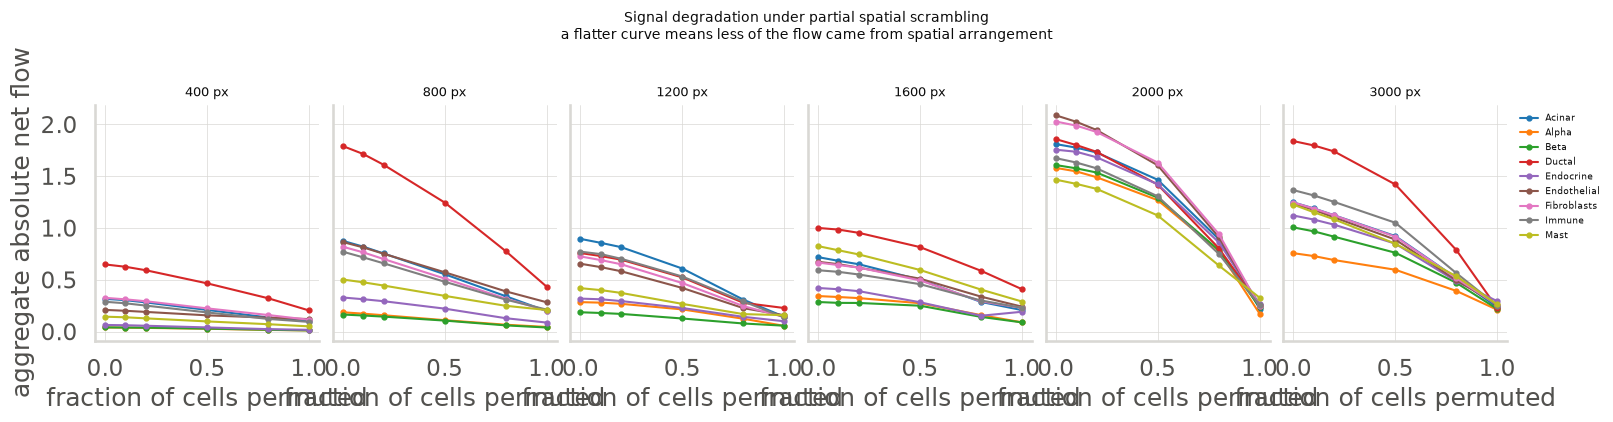

,fraction,0.0,0.1,0.2,0.5,0.8,1.0,retained_at_100pct
arm,window_size,,,,,,,
w400,400,0.230,0.221,0.207,0.159,0.111,0.080,0.347
w800,800,0.700,0.660,0.613,0.460,0.292,0.190,0.271
w1200,1200,0.557,0.535,0.505,0.376,0.206,0.130,0.234
w1600,1600,0.613,0.593,0.569,0.464,0.295,0.219,0.357
w2000,2000,1.763,1.723,1.666,1.392,0.818,0.247,0.140
w3000,3000,1.226,1.177,1.117,0.916,0.528,0.246,0.200


In [32]:
# 3d. Partial permutation, per arm -- the degradation curves of Interaction_analysis.ipynb.
#
# Only a fraction of each window's cells is shuffled, so the x axis is "how much spatial
# arrangement was destroyed". A steep curve means the flow depended on arrangement; a flat one
# means it was already explained by composition, i.e. there was little spatial signal to lose.
ablation.fig_partial_permutation(partial)
plt.show()

# Slope of the degradation, per arm: signal at 0% shuffled vs at 100%.
deg = (
    partial[partial["condition"] == "all_samples"]
    .groupby(["arm", "window_size", "fraction"], as_index=False)["signal"].mean()
    .pivot_table(index=["arm", "window_size"], columns="fraction", values="signal")
    .sort_index(level="window_size")
)
deg["retained_at_100pct"] = deg[1.0] / deg[0.0]
deg.round(3)

In [33]:
# One row per arm, pulling the whole ablation together. Computed from the CSVs rather than written
# down, so it cannot drift from the data if the sweep or the extraction is re-run.
pooled = coverage[coverage["bin"] >= 0]

rows = []
for arm in extract.ARMS:
    if arm not in set(pooled["arm"]):
        continue
    win = ablation.load_windows(arm)
    cov_g = pooled[pooled["arm"] == arm].sort_values("d_mid_px")
    zero = cov_g[cov_g["pairs_covered"] == 0]
    att_g = attention[(attention["arm"] == arm) & (attention["bin"] >= 0)]
    glob = att_g[att_g["d_lo_px"] >= 110]
    rec_g = recovery[recovery["arm"] == arm]
    perm_g = permutation[(permutation["arm"] == arm)
                         & (permutation["condition"] == "all_samples")
                         & (permutation["sender"] < permutation["receiver"])]
    n_sig = perm_g.groupby("seed")["p"].apply(lambda p: (p < 0.05).sum())

    rows.append({
        "window_px": extract.arm_window_size(arm),
        "n_windows": len(win["n_cells"]),
        "cells_per_window": round(float(win["n_cells"].mean()), 1),
        "pair_coverage": round(cov_g["pairs_covered"].sum() / cov_g["pairs_possible"].sum(), 4),
        "reach_px": float(zero["d_lo_px"].iloc[0]) if len(zero) else np.nan,
        "mass_beyond_110px": round(float(glob.groupby("seed")["mass_share"].sum().mean()), 3),
        "r_vs_w3000": round(float(rec_g["pearson_vs_reference"].mean()), 3),
        "n_sig_of_36": round(float(n_sig.mean()), 1),
        "val_ccc": round(float(runs[runs["arm"] == arm]["val_concordance_corr"].mean()), 4),
    })

summary = pd.DataFrame(rows)
print("pair_coverage      fraction of same-FOV cell pairs that ever share a window")
print("reach_px           first distance bin the arm covers ZERO pairs in -- its hard ceiling")
print("mass_beyond_110px  share of off-diagonal relevance beyond the local graph radius")
print("r_vs_w3000         Pearson r of the off-diagonal flow matrix vs the widest arm")
print(f"n_sig_of_36        significant interactions (p<0.05), of 36 independent pairs; "
      f"seed ceiling r = {recovery['seed_ceiling'].iloc[0]:.3f}\n")
summary

pair_coverage      fraction of same-FOV cell pairs that ever share a window
reach_px           first distance bin the arm covers ZERO pairs in -- its hard ceiling
mass_beyond_110px  share of off-diagonal relevance beyond the local graph radius
r_vs_w3000         Pearson r of the off-diagonal flow matrix vs the widest arm
n_sig_of_36        significant interactions (p<0.05), of 36 independent pairs; seed ceiling r = -0.092



,window_px,n_windows,cells_per_window,pair_coverage,reach_px,mass_beyond_110px,r_vs_w3000,n_sig_of_36,val_ccc
0,400.0,3426,44.2,0.0083,600.0,0.760,0.537,22.0,0.0180
1,800.0,875,173.3,0.0312,1200.0,0.922,0.586,24.3,0.0165
2,1200.0,496,305.6,0.0707,2000.0,0.964,-0.173,25.3,0.0148
3,1600.0,300,505.3,0.1135,3000.0,0.966,0.572,19.0,0.0156
4,2000.0,150,1010.6,0.1752,3000.0,0.988,0.049,30.3,0.0159
5,3000.0,100,1516.0,0.3668,NaN,0.992,0.495,25.0,0.0138


## What the ablation shows

Six window sizes × 3 seeds, sweep [`z63vmk20`](https://wandb.ai/francesca-drummer/InterScale_hyperparameter_sweep/sweeps/z63vmk20),
attention extracted on the held-out slide `Run5211_S3`.

### 1. The window size sets a hard ceiling on which interactions can exist — this is definitive

Pure geometry, no model, no seeds. Fraction of same-FOV cell pairs that ever share a window:

| window | overall coverage | reach (first bin with **zero** pairs) |
|---|---|---|
| 400 px | 0.8 % | 600 px |
| 800 px | 3.1 % | 800 px |
| 1200 px | 7.1 % | 1200 px |
| 1600 px | 11.4 % | 1600 px |
| 2000 px | 17.5 % | 2000 px |
| 3000 px | 36.7 % | 4000 px |

A pair beyond an arm's reach never enters the same attention block — not weakly, not for any seed,
not with more training. At 800–1200 px separation the w400 arm covers **0.000** of pairs while
w3000 covers **0.712**. Even the widest arm sees only just over a third of the pairs within an FOV.

### 2. Attention is spread almost uniformly over whatever the window exposes

`fig_attention_distance` **B** is the most informative panel: within each arm, mean relevance per
pair is nearly **flat with distance** out to the window's edge.

| arm | per-pair relevance, 0–20 px | at its outermost bin | ratio |
|---|---|---|---|
| 400 px | 9.9×10⁻⁴ | 6.7×10⁻⁴ (400–600 px) | 1.5× |
| 3000 px | 2.0×10⁻⁵ | 1.1×10⁻⁵ (4000–6600 px) | 1.7× |

A factor of ~1.6 decay across two to three orders of magnitude in distance. The model does **not**
preferentially weight nearby cells.

The consequence is the real finding: because per-pair weight is roughly distance-independent, the
*total* relevance mass at each distance is driven almost entirely by **how many pairs the windowing
exposes there**. The window size does not merely limit what is visible — it effectively
**determines the interaction range the model reports**. Each arm's mass peaks at its own window
scale and falls off a cliff at its reach.

Also: 76 % (w400) → 99 % (w3000) of off-diagonal relevance sits **beyond the 110 px local-graph
radius**, i.e. beyond what the GCN component could supply. These are highly seed-stable
(sd 0.0007–0.028).

### 3. Which *cell-type* interactions are missed cannot be answered from these models

Reported as a negative result rather than dressed up:

- **The net-flow matrix does not reproduce across seeds.** 4 of 6 arms have between-seed Pearson
  r < 0.5; the worst seed pair reaches **r = −0.76**, and w3000 — the reference — sits at
  **−0.09** against itself. `Ductal→Acinar`, the largest single entry, is +0.69 / −0.37 / +0.17
  across the three seeds.
- **The permutation test does not discriminate between arms.** 0 of 36 interactions are never
  significant, and 24 of 36 are already significant at 400 px. The within-window label-shuffle null
  is rejected for 17–31 of 36 pairs at *every* window size, so it detects "there is spatial
  structure" (always true) rather than separating window sizes. Seeds agree on *which* pairs only
  at Jaccard 0.37–0.73.
- **`z` is not comparable across arms** — `null_std` shrinks with the number of windows averaged
  over, which spans 3426 → 100.
- The underlying reason is visible in the sweep itself: **every arm sits at val R² ≈ 0** (val CCC
  0.014–0.018), i.e. indistinguishable from predicting the per-gene mean. A model that does not fit
  the target has no reason to place a reproducible interaction structure in its attention.

### What would make level 3 answerable

1. **A model that fits.** The hyperparameters here are the winner of the reconstruction sweep
   `sio2fsjm`, whose own best trial reaches R² ≈ 0 on this dataset. Until reconstruction is above
   chance, per-pair interaction claims rest on nothing.
2. **More seeds** — 3 cannot separate signal from seed at r ≈ 0. 10+ would at least put an error
   bar on it.
3. **A null that scales with the window.** Fix the number of windows aggregated per arm (subsample
   the small-window arms) so `z` is comparable, or use a null that breaks long-range structure
   specifically rather than all within-window arrangement.

Levels 1 and 2 stand on their own and need none of this.